# Testing How QSVMs work

All credits to https://medium.com/mit-6-s089-intro-to-quantum-computing/quantum-support-vector-machine-qsvm-134eff6c9d3b
Though that article uses an outdated version of Qiskit. Here I plan to provided an explanation of how my first introduction to Qiskit has been and explanation to the new concepts introduced by QSVMs

In [ ]:
%pip install -U qiskit qiskit-machine-learning qiskit-aer
pip install pylatexenc

  Using cached qiskit-2.6.0-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (14 kB)
  Using cached qiskit_aer-0.18.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (8.7 kB)
Using cached qiskit-2.6.0-cp310-abi3-manylinux_2_28_x86_64.whl (10.1 MB)
Using cached qiskit_aer-0.18.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (14.2 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [qiskit-aer]2 [qiskit-aer]
Note: you may need to restart the kernel to use updated packages.


In [51]:
import qiskit
print(qiskit.__version__)
from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit import QuantumCircuit, transpile
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

2.6.0


In [2]:
feature_dim = 2
seed = 42

Here we just use the function ad_hoc_data() to create random testing data

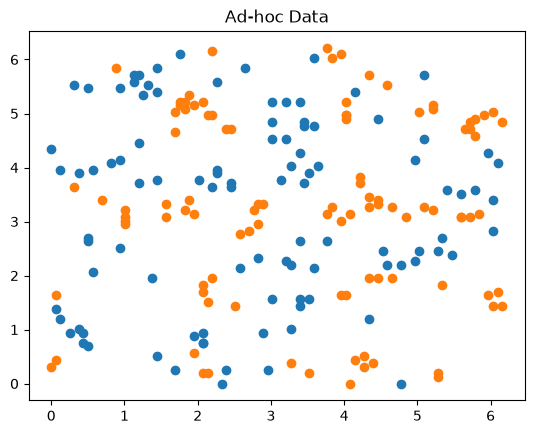

In [ ]:
x_train, y_train, x_test, y_test, class_labels = ad_hoc_data (
    training_size = 100,
    test_size = 40,
    n = feature_dim,
    gap = 0.3,
    plot_data = True,
    one_hot = False,
    include_sample_total = True,
)

Here whe setup our backend. Which means that we are using our own computer to simulate what an actual quantum computer would do in place. In this case we tell qiskit that we need it to simulate our quantum circuit (random) 1024 times. The quantum circuit I'm talking about will become clearer later; just know that right now we have all of our qbits in $\Ket{0}$

In [4]:
backend = BasicSimulator()
backend.set_options (
    shots = 1024,
    seed_simulator = seed,
)

Now we define a feature map; meaning that we are defining a way to transform our ordinary data from our dataset into rotation angles for our qbits. The way we are doing that is defined by the circuit below where we define how our qbits will behave and how many do we want.

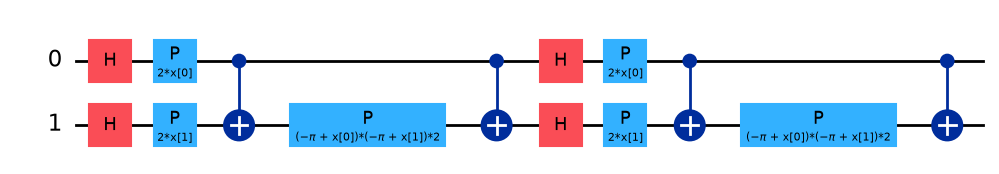

In [5]:
feature_map = zz_feature_map(
    feature_dimension=feature_dim,
    reps = 2,
    entanglement = "linear"
)

feature_map.draw("mpl")

This diagram shows 

In [7]:
quantum_kernel = FidelityQuantumKernel (
    feature_map=feature_map,
)

In [ ]:
kernel_train = quantum_kernel.evaluate(x_train)
kernel_test = quantum_kernel.evaluate(x_test,x_train)
print(kernel_train.shape)
print(kernel_test.shape)

(200, 200)
(80, 200)


In [9]:
qsvc = QSVC(quantum_kernel=quantum_kernel)
qsvc.fit(x_train,y_train)
qsvc_score=qsvc.score(x_test,y_test)
print(f"QSVC test score: {qsvc_score}")

QSVC test score: 1.0


## Trying out QSVC with Iris

In [12]:
iris = load_iris()
x = iris.data
y = iris.target
X_train, X_test, Y_train,Y_test = train_test_split (
    x,y,test_size = 0.2 , random_state = seed
)

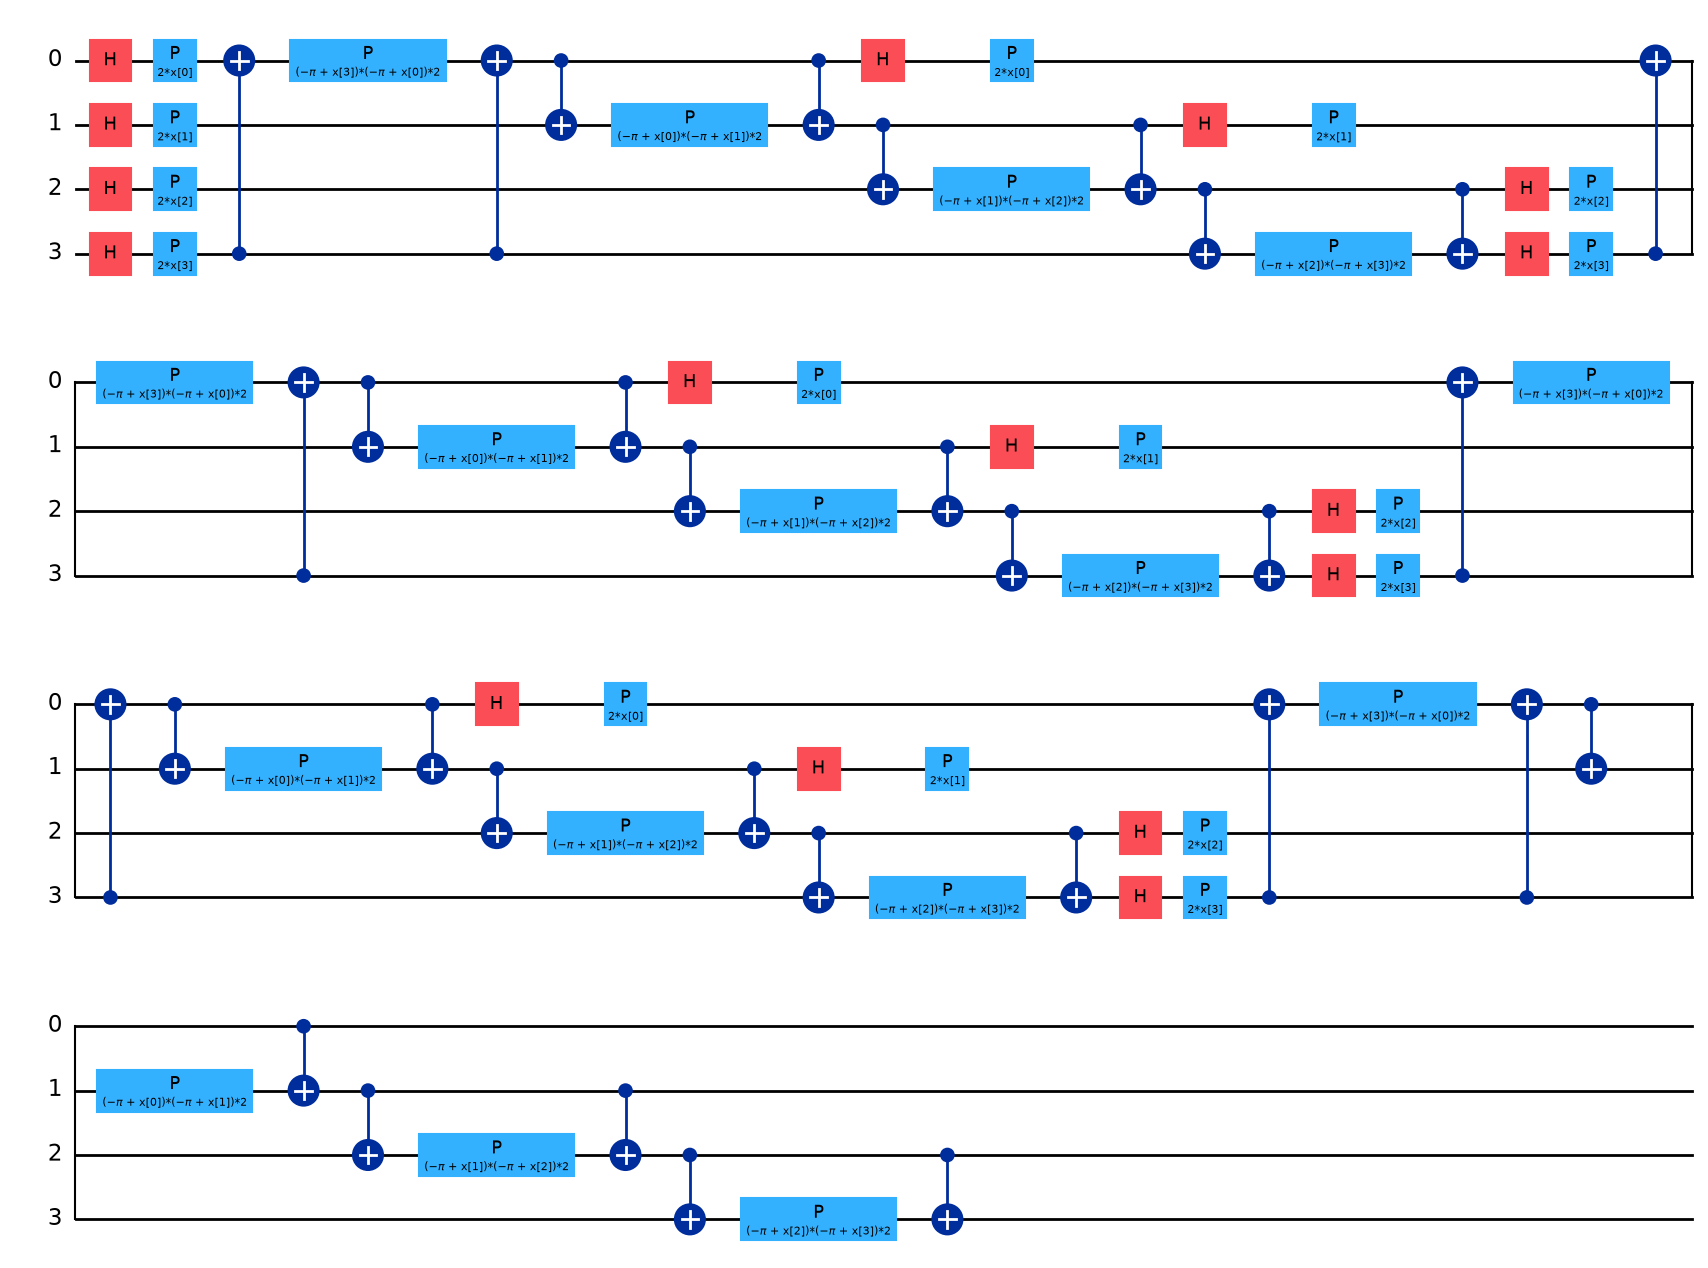

In [53]:
feature_map_iris =zz_feature_map(
    feature_dimension = 4,
    reps = 4,
    entanglement = "circular",
)
feature_map_iris.draw("mpl")

In [54]:
kernel = FidelityQuantumKernel (
    feature_map = feature_map_iris
)
qsvc_iris = QSVC(quantum_kernel=kernel)
qsvc_iris.fit(X_train,Y_train)
qsvc_iris.score(X_test,Y_test)


0.6666666666666666

Though we technically did not do anything different from what we did before, it is wrong because we did not preprocess the data, we did not encode our features as angles so that our quantum model could work with them effectively. For that we need to do the following

In [55]:
x[0]

array([5.1, 3.5, 1.4, 0.2])

In [56]:
scaler = MinMaxScaler(feature_range=(0,np.pi))
x_scaled = scaler.fit_transform(x)
x_scaled[0]
X_train, X_test, Y_train,Y_test = train_test_split (
    x_scaled,y,test_size = 0.2 , random_state = seed
)
qsvc_iris.fit(X_train,Y_train)
qsvc_iris.score(X_test,Y_test)

0.6666666666666666

In [62]:
Y_pred = qsvc_iris.predict(X_test)

print(confusion_matrix(Y_test,Y_pred))
print(classification_report(Y_test,Y_pred, target_names = iris.target_names))

[[3 4 3]
 [0 8 1]
 [1 1 9]]
              precision    recall  f1-score   support

      setosa       0.75      0.30      0.43        10
  versicolor       0.62      0.89      0.73         9
   virginica       0.69      0.82      0.75        11

    accuracy                           0.67        30
   macro avg       0.69      0.67      0.64        30
weighted avg       0.69      0.67      0.64        30

